In [1]:
import torch
from torch import nn


In [2]:
# set the device the agnostic code

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [13]:
from requests.api import request
import requests
import zipfile
from pathlib import Path


# set the data path and image path
data_path = Path("data")
image_path = data_path / "pizza_steak_sushi"
zip_file_name = "pizza_steak_sushi.zip"
# check if the image_path directory exists
if image_path.is_dir():
  print(f"{image_path} directory exists.")
else:
  print(f"Did not find {image_path} directory, creating one...")
  # Create the image_path directory first
  image_path.mkdir(parents=True, exist_ok=True)

  # Define the full path for the zip file within the created directory
  zip_file_path = image_path / zip_file_name

  # Download the zip file
  print(f"Downloading {zip_file_name} data to {zip_file_path}...")
  # Correct the typo: requsts.get -> requests.get
  response = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")

  with open(zip_file_path, "wb") as f:
    f.write(response.content)

  # Unzip the file
  with zipfile.ZipFile(zip_file_path, "r") as zip_ref:
    print(f"Unzipping {zip_file_name} data into {image_path}...")
    zip_ref.extractall(image_path)


data\pizza_steak_sushi directory exists.


In [14]:
import os
# create function to walk through our datasets
def walk_through_dir(dir_path):
  for dirpath,dirnames,filenames in os.walk(dir_path):
    print(f" there are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}' ")

In [15]:
walk_through_dir(image_path)

 there are 2 directories and 1 images in 'data\pizza_steak_sushi' 
 there are 3 directories and 0 images in 'data\pizza_steak_sushi\test' 
 there are 0 directories and 25 images in 'data\pizza_steak_sushi\test\pizza' 
 there are 0 directories and 19 images in 'data\pizza_steak_sushi\test\steak' 
 there are 0 directories and 31 images in 'data\pizza_steak_sushi\test\sushi' 
 there are 3 directories and 0 images in 'data\pizza_steak_sushi\train' 
 there are 0 directories and 78 images in 'data\pizza_steak_sushi\train\pizza' 
 there are 0 directories and 75 images in 'data\pizza_steak_sushi\train\steak' 
 there are 0 directories and 72 images in 'data\pizza_steak_sushi\train\sushi' 


In [16]:
# create train and test path
train_dir= image_path / "train"
test_dir= image_path / "test"
train_dir, test_dir

(WindowsPath('data/pizza_steak_sushi/train'),
 WindowsPath('data/pizza_steak_sushi/test'))

Random image path: data\pizza_steak_sushi\train\pizza\68684.jpg
Image class: pizza
Image height: 384
Image width: 512
Image channels: RGB
<class 'PIL.JpegImagePlugin.JpegImageFile'>
<class 'numpy.ndarray'>


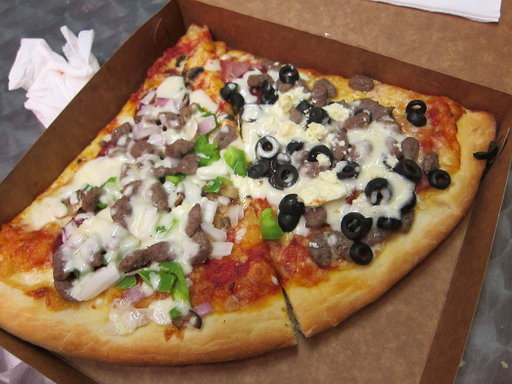

In [67]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# get all image paths
image_path_list=list(image_path.glob("*/*/*.jpg"))
# get a random image
random_image_path=random.choice(image_path_list)
# get the class of the image
image_class=random_image_path.parent.name
# open the image
img=Image.open(random_image_path)     # A PIL Image it gives u (hight,width)
img1=plt.imread(random_image_path)    # Matplotlib numpy array ( hight width channel )


# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
print(f"Image channels: { img.mode}")



print(type(img))
print(type(img1))




img



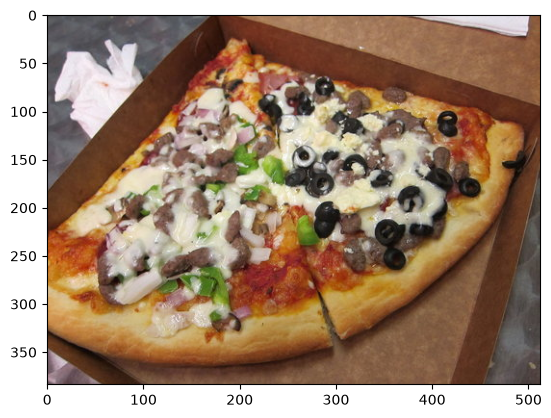

In [69]:
#turing our images into arrays
import numpy as np
import matplotlib.pyplot as plt


img_as_array=np.array(img)
img_as_array

plt.imshow(img_as_array)   # to print the img with plt u have to convet it to numpy arrary first 

In [70]:
import torch 
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from torch import nn


In [71]:
data_transform=transforms.Compose([
    # resize the image
    transforms.Resize(size=(64,64)),
    # Flip the images randomly on the horizontal for data augmentation
    transforms.RandomHorizontalFlip(p=0.5), # p = probability of flip, 0.5 = 50% chance
    # Turn the image into a torch.Tensor
    transforms.ToTensor()
])

In [75]:
data_transform(img).dtype,data_transform(img).shape

(torch.float32, torch.Size([3, 64, 64]))

In [76]:


data_transform1=transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Resize(size=(64,64))
])
            

     

 
    



In [74]:
data_transform(img).dtype,data_transform(img).shape

(torch.float32, torch.Size([3, 64, 64]))

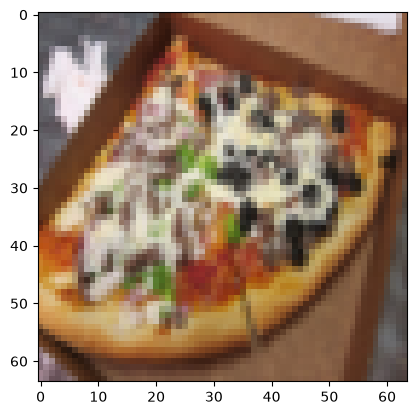

In [123]:
plt.imshow(data_transform(img).permute(1,2,0)) 
# we use permute because PyTorch and matplotlib expect the dimensions in different orders zero means color channels 

In [ ]:
fig,ax =plt.subplots(nrows=3,ncols=2,figsize=(7,7)) 
ax[0, 0].set_title("row 0, left")
ax[0, 1].set_title("row 0, right")
ax[1, 0].set_title("row 0, left")
ax[1, 1].set_title("row 0, right")
for axis in ax.flat:
    axis.axis("off")

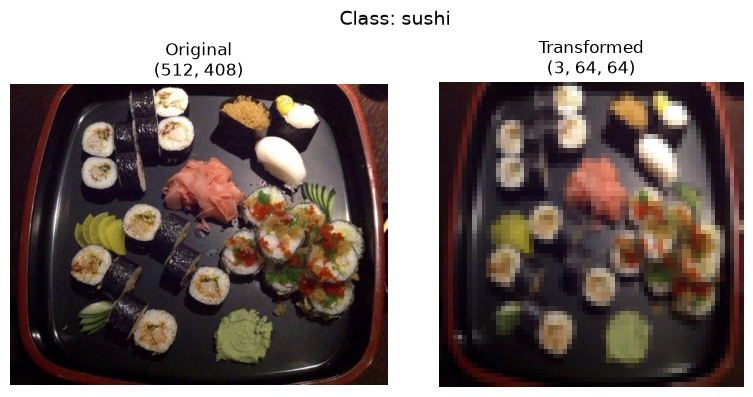

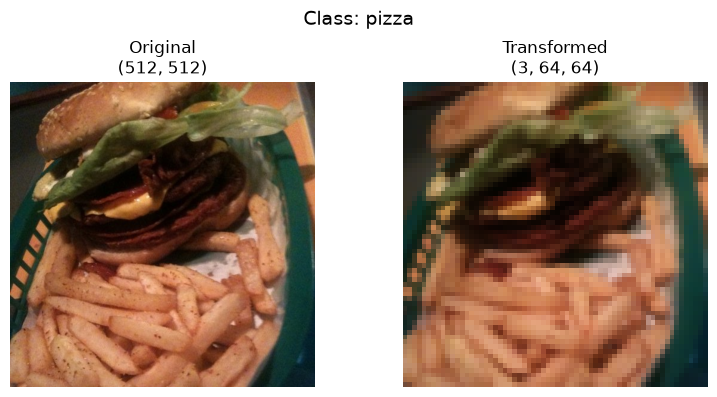

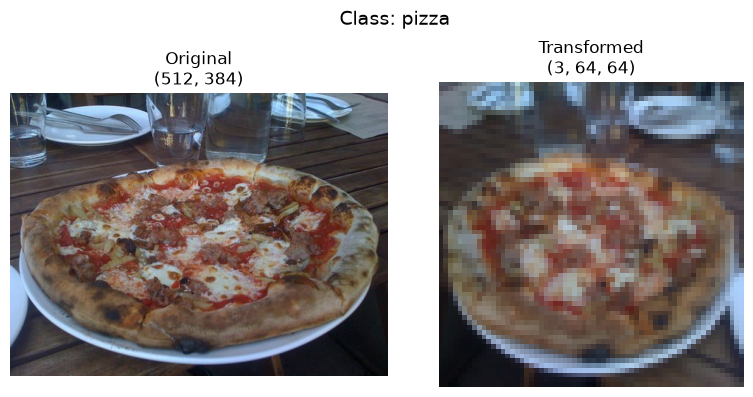

In [ ]:
def plot_transform_image(image_paths, transform, n=3, seed=None):
    """Plot n random images, each in its OWN figure: original (left) vs transformed (right)."""
    if seed is not None:
        random.seed(seed)

    # pick n DIFFERENT images, once
    random_image_paths = random.sample(image_paths, k=n)

    for path in random_image_paths:
        image = Image.open(path)
        transformed = transform(image)          # [C, H, W]
        class_name = path.parent.name           # e.g. "sushi"

        # a NEW figure for every image: 1 row, 2 columns
        fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(8, 4))
        fig.suptitle(f"Class: {class_name}", fontsize=14)

        # left: original (PIL image, no permute needed)
        ax[0].imshow(image)
        ax[0].set_title(f"Original\n{image.size}")
        ax[0].axis("off")

        # right: transformed (tensor -> [H, W, C] for matplotlib)
        ax[1].imshow(transformed.permute(1, 2, 0))
        ax[1].set_title(f"Transformed\n{tuple(transformed.shape)}")
        ax[1].axis("off")

        plt.tight_layout()
        plt.show()                              # show this figure before making the next one


plot_transform_image(image_path_list, data_transform, n=3, seed=42)

In [ ]:
# ImageFolder: folder names become the class labels
train_data = datasets.ImageFolder(root=train_dir,            # the folder
                                  transform=data_transform)  # applied to each image

test_data = datasets.ImageFolder(root=test_dir,
                                 transform=data_transform)

print(train_data.classes)        # ['pizza', 'steak', 'sushi']
print(train_data.class_to_idx)   # {'pizza': 0, 'steak': 1, 'sushi': 2}
print(len(train_data), len(test_data))

img, label = train_data[0]       # one sample: (image tensor, label number)
print(img.shape, label)

In [ ]:
# plot one image: imshow + axis off + label
img, label = train_data[0]                # (image tensor, label number)

plt.figure(figsize=(5, 5))
plt.imshow(img.permute(1, 2, 0))          # [C, H, W] -> [H, W, C] for matplotlib
plt.axis("off")                           # hide the axis (numbers + border)
plt.title(f"{train_data.classes[label]} | {tuple(img.shape)}", fontsize=14)  # e.g. "pizza"
plt.show()